# 📊 Perbandingan Metode LSTM, GRU, dan CNN pada Peramalan Volatilitas Kurs USD/IDR

**Referensi:** Septani, A.V., Afendi, F.M., & Kurnia, A. (2025). *Limits: Journal of Mathematics and Its Applications*, 22(1), 149–169.

---
**Pipeline Analisis:**
1. Eksplorasi Data (EDA)
2. Preprocessing & Perhitungan Volatilitas (Squared Return)
3. Sliding Window Cross-Validation (4 kelompok)
4. Hyperparameter Tuning — LSTM, GRU, CNN
5. Evaluasi Model (RMSE + Selang Kepercayaan 95%)
6. Peramalan 30 Hari ke Depan dengan Model Terbaik
7. Export hasil → siap untuk Streamlit Dashboard


## ⚙️ 1. Install & Import Library

In [1]:
# Install library yang dibutuhkan
!pip install scikit-learn tensorflow keras matplotlib seaborn openpyxl joblib -q

print("✅ Semua library berhasil diinstall")


✅ Semua library berhasil diinstall


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Stats & ML
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from scipy.stats import norm

# Deep Learning
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, GRU, Dense, Dropout, Conv1D, MaxPooling1D, Flatten
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, SGD

# Randomized Search
from sklearn.model_selection import ParameterSampler

# Seed untuk reprodusibilitas
import random
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

# Style plot
plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'LSTM': '#3498db', 'GRU': '#2ecc71', 'CNN': '#f39c12', 'Aktual': '#2c3e50'}

print("✅ Semua library berhasil diimport")
print(f"   TensorFlow version: {tf.__version__}")


✅ Semua library berhasil diimport
   TensorFlow version: 2.20.0


## 📂 2. Upload & Load Data

In [3]:
# Upload file Excel dari lokal
from google.colab import files
print("Silakan upload file: Data_Historis_USD_IDR.xlsx")
uploaded = files.upload()


Silakan upload file: Data_Historis_USD_IDR.xlsx


Saving Data Historis USD_IDR.xlsx to Data Historis USD_IDR.xlsx


In [4]:
# ── Load & Bersihkan Data ──────────────────────────────────────

def clean_price(x):
    """Konversi format harga Indonesia (titik ribuan, koma desimal) ke float."""
    if isinstance(x, str):
        x = x.strip().replace('.', '').replace(',', '.')
        # Hapus satuan 'K' jika ada
        x = x.replace('K', '').replace('k', '')
        try:
            return float(x)
        except:
            return np.nan
    elif isinstance(x, (int, float)):
        return float(x)
    return np.nan

def parse_tanggal(x):
    """
    Parse tanggal dari Excel.
    Masalah: openpyxl kadang membaca DD/MM/YYYY sebagai datetime(YYYY, MM, DD)
    (menukar bulan & hari jika DD <= 12).
    Solusi: untuk nilai datetime, swap kembali month <-> day.
    """
    if isinstance(x, pd.Timestamp):
        # Timestamp dari pandas → swap month dan day
        try:
            return pd.Timestamp(x.year, x.day, x.month)
        except:
            return pd.NaT
    elif hasattr(x, 'year'):  # datetime.datetime
        try:
            return pd.Timestamp(x.year, x.day, x.month)
        except:
            return pd.NaT
    elif isinstance(x, str):
        # String format DD/MM/YYYY → parse dengan dayfirst=True
        try:
            return pd.to_datetime(x, dayfirst=True)
        except:
            return pd.NaT
    return pd.NaT

# Load
file_name = list(uploaded.keys())[0]
df_raw = pd.read_excel(file_name)
print(f"Raw shape: {df_raw.shape}")
print(df_raw.head(3))


Raw shape: (2556, 6)
               Tanggal  Terakhir Pembukaan Tertinggi  Terendah Perubahan%
0  2026-05-06 00:00:00  18.015,0  18.065,0  18.065,0  18.007,5     -0,06%
1  2026-04-06 00:00:00  18.025,0  17.980,0  18.050,0  17.980,0      0,45%
2  2026-03-06 00:00:00  17.945,0  17.877,5  17.960,0  17.875,0      0,62%


In [5]:
# ── Preprocessing ─────────────────────────────────────────────

PERIODE_MULAI = '2016-06-06'
PERIODE_AKHIR = '2026-06-05'

df = df_raw.copy()
df['Tanggal'] = df['Tanggal'].apply(parse_tanggal)
df['Kurs'] = df['Terakhir'].apply(clean_price)

# Ambil kolom yang diperlukan
df = df[['Tanggal', 'Kurs']].dropna()

# Filter sesuai periode data: 6 Juni 2016 – 5 Juni 2026
df = df[(df['Tanggal'] >= PERIODE_MULAI) & (df['Tanggal'] <= PERIODE_AKHIR)]

# Sort ascending & reset index
df = df.sort_values('Tanggal').reset_index(drop=True)

# Drop duplikat tanggal (ambil yang pertama muncul)
df = df.drop_duplicates(subset='Tanggal', keep='first').reset_index(drop=True)

print(f"✅ Data bersih: {len(df)} observasi")
print(f"   Rentang: {df['Tanggal'].min().date()} s.d. {df['Tanggal'].max().date()}")
print(f"   Kurs Min: {df['Kurs'].min():,.1f} | Max: {df['Kurs'].max():,.1f}")
print()
print(df.describe())


✅ Data bersih: 2556 observasi
   Rentang: 2016-06-06 s.d. 2026-06-05
   Kurs Min: 12,947.5 | Max: 18,025.0

                             Tanggal          Kurs
count                           2556   2556.000000
mean   2021-06-04 00:37:44.788732160  14788.102308
min              2016-06-06 00:00:00  12947.500000
25%              2018-11-15 18:00:00  14026.500000
50%              2021-06-05 12:00:00  14515.000000
75%              2023-12-26 06:00:00  15615.000000
max              2026-06-05 00:00:00  18025.000000
std                              NaN   1112.611003


## 📈 3. Perhitungan Return & Volatilitas

In [6]:
# ── Log Return (Rt = ln(yt / yt-1)) ──────────────────────────

df['Return'] = np.log(df['Kurs'] / df['Kurs'].shift(1))
df['Volatilitas'] = df['Return'] ** 2   # Squared Return = proxy volatilitas

# Drop baris pertama (NaN return)
df = df.dropna().reset_index(drop=True)

print(f"✅ Return & Volatilitas dihitung")
print(f"   Total observasi: {len(df)}")
print(f"\nStatistik Return:")
print(df['Return'].describe())
print(f"\nStatistik Volatilitas (Squared Return):")
print(df['Volatilitas'].describe())


✅ Return & Volatilitas dihitung
   Total observasi: 2555

Statistik Return:
count    2555.000000
mean        0.000116
std         0.003578
min        -0.027844
25%        -0.001269
50%         0.000000
75%         0.001669
max         0.044659
Name: Return, dtype: float64

Statistik Volatilitas (Squared Return):
count    2.555000e+03
mean     1.281085e-05
std      6.149626e-05
min      0.000000e+00
25%      3.804522e-07
50%      2.027381e-06
75%      8.972520e-06
max      1.994416e-03
Name: Volatilitas, dtype: float64


## 🔍 4. Eksplorasi Data (EDA)

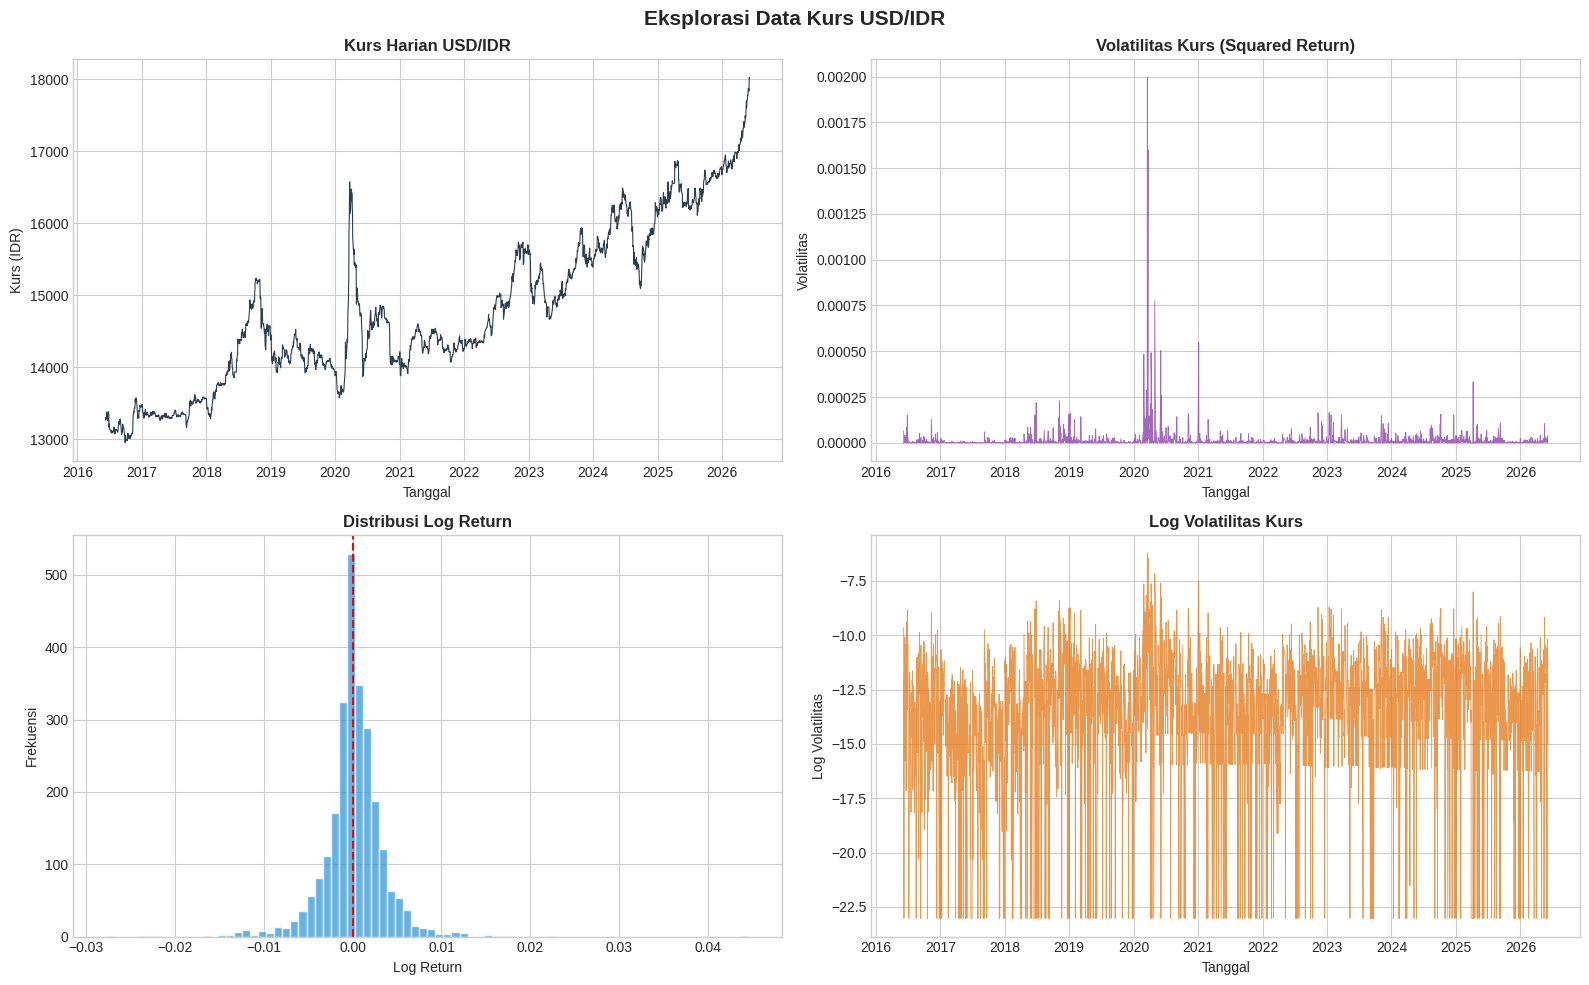

✅ Plot EDA disimpan: eda_kurs.png


In [7]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Eksplorasi Data Kurs USD/IDR', fontsize=15, fontweight='bold')

# Plot 1: Time series kurs harian
axes[0, 0].plot(df['Tanggal'], df['Kurs'], color=COLORS['Aktual'], linewidth=0.8)
axes[0, 0].set_title('Kurs Harian USD/IDR', fontweight='bold')
axes[0, 0].set_xlabel('Tanggal'); axes[0, 0].set_ylabel('Kurs (IDR)')
axes[0, 0].xaxis.set_major_locator(mdates.YearLocator())
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Plot 2: Volatilitas (squared return)
axes[0, 1].plot(df['Tanggal'], df['Volatilitas'], color='#8e44ad', linewidth=0.6, alpha=0.8)
axes[0, 1].set_title('Volatilitas Kurs (Squared Return)', fontweight='bold')
axes[0, 1].set_xlabel('Tanggal'); axes[0, 1].set_ylabel('Volatilitas')
axes[0, 1].xaxis.set_major_locator(mdates.YearLocator())
axes[0, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Plot 3: Distribusi Return
axes[1, 0].hist(df['Return'], bins=80, color='#3498db', alpha=0.75, edgecolor='white')
axes[1, 0].axvline(0, color='red', linestyle='--', linewidth=1.5)
axes[1, 0].set_title('Distribusi Log Return', fontweight='bold')
axes[1, 0].set_xlabel('Log Return'); axes[1, 0].set_ylabel('Frekuensi')

# Plot 4: Log Volatilitas
axes[1, 1].plot(df['Tanggal'], np.log(df['Volatilitas'] + 1e-10), color='#e67e22', linewidth=0.6, alpha=0.8)
axes[1, 1].set_title('Log Volatilitas Kurs', fontweight='bold')
axes[1, 1].set_xlabel('Tanggal'); axes[1, 1].set_ylabel('Log Volatilitas')
axes[1, 1].xaxis.set_major_locator(mdates.YearLocator())
axes[1, 1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.tight_layout()
plt.savefig('eda_kurs.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot EDA disimpan: eda_kurs.png")


In [8]:
# Statistik Deskriptif
print("=" * 55)
print("STATISTIK DESKRIPTIF DATA KURS USD/IDR")
print("=" * 55)
stats_df = pd.DataFrame({
    'Kurs': df['Kurs'].describe(),
    'Return': df['Return'].describe(),
    'Volatilitas': df['Volatilitas'].describe()
})
print(stats_df.round(8))
print()

# Identifikasi periode volatilitas tinggi
top5_vol = df.nlargest(5, 'Volatilitas')[['Tanggal', 'Kurs', 'Return', 'Volatilitas']]
print("Top 5 Hari Volatilitas Tertinggi:")
print(top5_vol.to_string(index=False))


STATISTIK DESKRIPTIF DATA KURS USD/IDR
               Kurs       Return   Volatilitas
count   2555.000000  2555.000000  2.555000e+03
mean   14788.654403     0.000116  1.281000e-05
std     1112.478557     0.003578  6.150000e-05
min    12947.500000    -0.027844  0.000000e+00
25%    14028.000000    -0.001269  3.800000e-07
50%    14515.000000     0.000000  2.030000e-06
75%    15615.000000     0.001669  8.970000e-06
max    18025.000000     0.044659  1.994420e-03

Top 5 Hari Volatilitas Tertinggi:
   Tanggal    Kurs    Return  Volatilitas
2020-03-19 15912.5  0.044659     0.001994
2020-03-23 16575.0  0.040005     0.001600
2020-04-30 14875.0 -0.027844     0.000775
2021-01-04 13885.0 -0.023397     0.000547
2020-06-03 14095.0 -0.022449     0.000504


## 🗂️ 5. Pembagian Data — Sliding Window Cross-Validation

In [9]:
# ── Sliding Window Cross-Validation (4 Kelompok) ─────────────
# Periode data: 6 Juni 2016 – 5 Juni 2026 (~10 tahun)
# Dibagi 4 kelompok masing-masing ~2.5 tahun

# Tentukan batas kelompok berdasarkan tanggal aktual data
group_bounds = [
    ('Kelompok 1', '2016-06-06', '2018-12-31'),   # ~2.6 tahun
    ('Kelompok 2', '2019-01-01', '2021-06-30'),   # ~2.5 tahun
    ('Kelompok 3', '2021-07-01', '2023-12-31'),   # ~2.5 tahun
    ('Kelompok 4', '2024-01-01', '2026-06-05'),   # ~2.5 tahun (s.d. akhir data)
]

groups = []
for name, start, end in group_bounds:
    mask = (df['Tanggal'] >= start) & (df['Tanggal'] <= end)
    g = df[mask].reset_index(drop=True)
    if len(g) > 20:
        groups.append((name, g))
        n_train = int(len(g) * 0.8)
        print(f"{name}: {start} s.d. {end}")
        print(f"  Total: {len(g)} obs | Train: {n_train} | Test: {len(g)-n_train}")

print()
print(f"Total {len(groups)} kelompok untuk hyperparameter tuning ✅")

# Final split seluruh data (80/20)
N = len(df)
n_train_full = int(N * 0.8)
df_train_full = df.iloc[:n_train_full].reset_index(drop=True)
df_test_full  = df.iloc[n_train_full:].reset_index(drop=True)
print(f"\nFull split (80/20):")
print(f"  Train: {len(df_train_full)} obs ({df_train_full['Tanggal'].min().date()} s.d. {df_train_full['Tanggal'].max().date()})")
print(f"  Test : {len(df_test_full)}  obs ({df_test_full['Tanggal'].min().date()} s.d. {df_test_full['Tanggal'].max().date()})")


Kelompok 1: 2016-06-06 s.d. 2018-12-31
  Total: 670 obs | Train: 536 | Test: 134
Kelompok 2: 2019-01-01 s.d. 2021-06-30
  Total: 625 obs | Train: 500 | Test: 125
Kelompok 3: 2021-07-01 s.d. 2023-12-31
  Total: 624 obs | Train: 499 | Test: 125
Kelompok 4: 2024-01-01 s.d. 2026-06-05
  Total: 636 obs | Train: 508 | Test: 128

Total 4 kelompok untuk hyperparameter tuning ✅

Full split (80/20):
  Train: 2044 obs (2016-06-07 s.d. 2024-06-21)
  Test : 511  obs (2024-06-24 s.d. 2026-06-05)


## 🛠️ 6. Fungsi Helper

In [10]:
# ── RMSE ──────────────────────────────────────────────────────
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# ── Selang Kepercayaan 95% ─────────────────────────────────────
def confidence_interval(sigma_pred, alpha=0.05):
    z = norm.ppf(1 - alpha/2)  # 1.96
    upper = z * sigma_pred
    lower = -z * sigma_pred
    return lower, upper

def pct_in_ci(y_actual, lower, upper):
    """Persentase nilai aktual yang berada dalam selang kepercayaan."""
    inside = np.sum((y_actual >= lower) & (y_actual <= upper))
    return 100 * inside / len(y_actual)

# ── Sequence Builder untuk DL ─────────────────────────────────
def create_sequences(data, lookback=10):
    X, y = [], []
    for i in range(lookback, len(data)):
        X.append(data[i-lookback:i])
        y.append(data[i])
    return np.array(X), np.array(y)

# ── Scaler ────────────────────────────────────────────────────
def scale_data(train, test):
    scaler = MinMaxScaler(feature_range=(0, 1))
    train_scaled = scaler.fit_transform(train.reshape(-1, 1)).ravel()
    test_scaled  = scaler.transform(test.reshape(-1, 1)).ravel()
    return train_scaled, test_scaled, scaler

print("✅ Fungsi helper siap")


✅ Fungsi helper siap


## 🧠 7. Pemodelan LSTM — Hyperparameter Tuning


In [11]:
# ── LSTM Hyperparameter Space ─────────────────────────────────
from scipy.stats import uniform, loguniform, randint as sp_randint

LOOKBACK    = 10
N_ITER_DL   = 20   # Jumlah kombinasi Random Search (lebih banyak = lebih optimal)

lstm_param_grid = {
    'optimizer'  : ['adam', 'rmsprop'],
    'activation' : ['relu', 'tanh', 'sigmoid'],
    'n_neurons'  : sp_randint(16, 129),          # nilai awal=16, nilai atas=128
    'dropout'    : uniform(0.1, 0.4),            # nilai awal=0.1, nilai atas=0.5 (range=0.4)
    'lr'         : loguniform(1e-4, 1e-1),       # nilai awal=0.0001, nilai atas=0.1 (log scale)
}

def build_lstm(n_neurons, activation, optimizer, dropout, lr, lookback):
    opt_map = {'adam': Adam(lr), 'rmsprop': RMSprop(lr), 'sgd': SGD(lr)}
    model = Sequential([
        LSTM(n_neurons, input_shape=(lookback, 1), activation=activation, return_sequences=False),
        Dropout(dropout),
        Dense(1)
    ])
    model.compile(optimizer=opt_map[optimizer], loss='mse')
    return model

# ── Tuning pada 4 Kelompok ────────────────────────────────────
print("LSTM Cross-Validation Tuning (Random Search)\n")
param_list = list(ParameterSampler(lstm_param_grid, n_iter=N_ITER_DL, random_state=SEED))
lstm_combo_results = []

for i, params in enumerate(param_list):
    avg_rmses = []
    for name, g in groups:
        vol = g['Volatilitas'].values
        n   = len(vol)
        n_tr = int(n * 0.8)

        tr_sc, te_sc, sc = scale_data(vol[:n_tr], vol[n_tr:])
        X_tr, y_tr = create_sequences(tr_sc, LOOKBACK)
        X_te, y_te = create_sequences(np.concatenate([tr_sc[-LOOKBACK:], te_sc]), LOOKBACK)
        X_tr = X_tr.reshape(-1, LOOKBACK, 1)
        X_te = X_te.reshape(-1, LOOKBACK, 1)

        tf.random.set_seed(SEED)
        m = build_lstm(params['n_neurons'], params['activation'], params['optimizer'],
                       params['dropout'], params['lr'], LOOKBACK)
        cb = EarlyStopping(patience=3, restore_best_weights=True, verbose=0)
        m.fit(X_tr, y_tr, epochs=10, batch_size=32, validation_split=0.1,
              callbacks=[cb], verbose=0)

        pred_sc = m.predict(X_te, verbose=0).ravel()
        pred    = sc.inverse_transform(pred_sc.reshape(-1,1)).ravel()
        actual  = sc.inverse_transform(y_te.reshape(-1,1)).ravel()
        avg_rmses.append(rmse(actual, pred))

    avg = np.mean(avg_rmses)
    lstm_combo_results.append({**params, 'avg_rmse': avg})
    if (i+1) % 5 == 0 or i == 0:
        print(f"  [{i+1}/{N_ITER_DL}] opt={params['optimizer']}, neurons={params['n_neurons']}, "
              f"act={params['activation']}, lr={params['lr']:.5f}, dropout={params['dropout']:.3f}, avg_RMSE={avg:.6f}")

# Best LSTM params
best_lstm = min(lstm_combo_results, key=lambda x: x['avg_rmse'])
print(f"\n✅ Best LSTM params:")
for k, v in best_lstm.items():
    print(f"   {k}: {v}")


LSTM Cross-Validation Tuning (Random Search)



  [1/20] opt=adam, neurons=87, act=sigmoid, lr=0.00036, dropout=0.419, avg_RMSE=0.000032
  [5/20] opt=adam, neurons=123, act=relu, lr=0.00684, dropout=0.347, avg_RMSE=0.000031
  [10/20] opt=rmsprop, neurons=68, act=tanh, lr=0.00082, dropout=0.423, avg_RMSE=0.000031
  [15/20] opt=rmsprop, neurons=30, act=tanh, lr=0.01520, dropout=0.471, avg_RMSE=0.000031
  [20/20] opt=adam, neurons=50, act=sigmoid, lr=0.01320, dropout=0.426, avg_RMSE=0.000031

✅ Best LSTM params:
   activation: tanh
   dropout: 0.4706635463175177
   lr: 0.015199034037054086
   n_neurons: 30
   optimizer: rmsprop
   avg_rmse: 3.086046704783872e-05


In [12]:
# ── LSTM Final Training pada Full Data ───────────────────────

train_vol_full = df_train_full['Volatilitas'].values
test_vol_full  = df_test_full['Volatilitas'].values

tr_sc_lstm, te_sc_lstm, sc_lstm = scale_data(train_vol_full, test_vol_full)

X_tr_lstm, y_tr_lstm = create_sequences(tr_sc_lstm, LOOKBACK)
X_te_lstm, y_te_lstm = create_sequences(
    np.concatenate([tr_sc_lstm[-LOOKBACK:], te_sc_lstm]), LOOKBACK)

X_tr_lstm = X_tr_lstm.reshape(-1, LOOKBACK, 1)
X_te_lstm = X_te_lstm.reshape(-1, LOOKBACK, 1)

tf.random.set_seed(SEED)
lstm_model = build_lstm(
    best_lstm['n_neurons'], best_lstm['activation'],
    best_lstm['optimizer'], best_lstm['dropout'], best_lstm['lr'], LOOKBACK
)

cb_lstm = [
    EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
]

history_lstm = lstm_model.fit(
    X_tr_lstm, y_tr_lstm, epochs=50, batch_size=32,
    validation_split=0.1, callbacks=cb_lstm, verbose=1
)

# Prediksi
pred_tr_lstm = sc_lstm.inverse_transform(lstm_model.predict(X_tr_lstm, verbose=0)).ravel()
pred_te_lstm = sc_lstm.inverse_transform(lstm_model.predict(X_te_lstm, verbose=0)).ravel()

act_tr_lstm = sc_lstm.inverse_transform(y_tr_lstm.reshape(-1,1)).ravel()
act_te_lstm = sc_lstm.inverse_transform(y_te_lstm.reshape(-1,1)).ravel()

rmse_lstm_train = rmse(act_tr_lstm, pred_tr_lstm)
rmse_lstm_test  = rmse(act_te_lstm, pred_te_lstm)

# Confidence Interval
lower_l_train, upper_l_train = confidence_interval(np.sqrt(np.abs(pred_tr_lstm)))
lower_l_test,  upper_l_test  = confidence_interval(np.sqrt(np.abs(pred_te_lstm)))

return_tr = df_train_full['Return'].values[LOOKBACK:]
return_te = df_test_full['Return'].values[:len(pred_te_lstm)]

pct_l_train = pct_in_ci(return_tr, lower_l_train, upper_l_train)
pct_l_test  = pct_in_ci(return_te, lower_l_test,  upper_l_test)

print(f"\n{'='*45}")
print(f"LSTM — Hasil Evaluasi (Best Config)")
print(f"{'='*45}")
print(f"RMSE  Training : {rmse_lstm_train:.7f}")
print(f"RMSE  Testing  : {rmse_lstm_test:.7f}")
print(f"% CI  Training : {pct_l_train:.2f}%")
print(f"% CI  Testing  : {pct_l_test:.2f}%")


Epoch 1/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0032 - val_loss: 1.0962e-04 - learning_rate: 0.0152
Epoch 2/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0017 - val_loss: 9.8224e-05 - learning_rate: 0.0152
Epoch 3/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0014 - val_loss: 4.8128e-04 - learning_rate: 0.0152
Epoch 4/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0014 - val_loss: 2.2294e-04 - learning_rate: 0.0152
Epoch 5/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0013 - val_loss: 9.6801e-05 - learning_rate: 0.0076
Epoch 6/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0013 - val_loss: 9.7890e-05 - learning_rate: 0.0076
Epoch 7/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0013 - val_loss: 9.7655e-05 - learning_rate: 0.0076
Epoch 8/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0012 - val_loss: 9.8909e-05 - learning_rate: 0.0038
Epoch 9/50
58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0012 - val_loss: 1.0205e-04 - learning_rate:

## 🔁 8. Pemodelan GRU — Hyperparameter Tuning


In [13]:
# ── GRU Hyperparameter Space ──────────────────────────────────
gru_param_grid = {
    'units'      : sp_randint(16, 257),          # nilai awal=16, nilai atas=256
    'lr'         : loguniform(1e-4, 1e-1),       # nilai awal=0.0001, nilai atas=0.1 (log scale)
    'dropout'    : uniform(0.1, 0.4),            # nilai awal=0.1, nilai atas=0.5 (range=0.4)
    'batch_size' : [16, 32, 64],
}

def build_gru(units, lr, dropout, lookback):
    model = Sequential([
        GRU(units, input_shape=(lookback, 1), return_sequences=False),
        Dropout(dropout),
        Dense(1)
    ])
    model.compile(optimizer=Adam(lr), loss='mse')
    return model

print("GRU Cross-Validation Tuning (Random Search)\n")
gru_param_list = list(ParameterSampler(gru_param_grid, n_iter=N_ITER_DL, random_state=SEED))
gru_combo_results = []

for i, params in enumerate(gru_param_list):
    avg_rmses = []
    for name, g in groups:
        vol  = g['Volatilitas'].values
        n    = len(vol)
        n_tr = int(n * 0.8)

        tr_sc, te_sc, sc = scale_data(vol[:n_tr], vol[n_tr:])
        X_tr, y_tr = create_sequences(tr_sc, LOOKBACK)
        X_te, y_te = create_sequences(np.concatenate([tr_sc[-LOOKBACK:], te_sc]), LOOKBACK)
        X_tr = X_tr.reshape(-1, LOOKBACK, 1)
        X_te = X_te.reshape(-1, LOOKBACK, 1)

        tf.random.set_seed(SEED)
        m = build_gru(params['units'], params['lr'], params['dropout'], LOOKBACK)
        cb = EarlyStopping(patience=3, restore_best_weights=True, verbose=0)
        m.fit(X_tr, y_tr, epochs=10, batch_size=params['batch_size'],
              validation_split=0.1, callbacks=[cb], verbose=0)

        pred_sc = m.predict(X_te, verbose=0).ravel()
        pred    = sc.inverse_transform(pred_sc.reshape(-1,1)).ravel()
        actual  = sc.inverse_transform(y_te.reshape(-1,1)).ravel()
        avg_rmses.append(rmse(actual, pred))

    avg = np.mean(avg_rmses)
    gru_combo_results.append({**params, 'avg_rmse': avg})
    if (i+1) % 5 == 0 or i == 0:
        print(f"  [{i+1}/{N_ITER_DL}] units={params['units']}, lr={params['lr']:.5f}, "
              f"dropout={params['dropout']:.3f}, batch={params['batch_size']}, avg_RMSE={avg:.6f}")

best_gru = min(gru_combo_results, key=lambda x: x['avg_rmse'])
print(f"\n✅ Best GRU params:")
for k, v in best_gru.items():
    print(f"   {k}: {v}")


GRU Cross-Validation Tuning (Random Search)

  [1/20] units=87, lr=0.00036, dropout=0.419, batch=64, avg_RMSE=0.000032
  [5/20] units=36, lr=0.00035, dropout=0.185, batch=32, avg_RMSE=0.000032
  [10/20] units=33, lr=0.00225, dropout=0.372, batch=64, avg_RMSE=0.000031
  [15/20] units=19, lr=0.00042, dropout=0.270, batch=32, avg_RMSE=0.000031
  [20/20] units=252, lr=0.00662, dropout=0.486, batch=32, avg_RMSE=0.000032

✅ Best GRU params:
   batch_size: 64
   dropout: 0.28369955678634684
   lr: 0.0010025956902289571
   units: 119
   avg_rmse: 3.107383981670309e-05


In [14]:
# ── GRU Final Training pada Full Data ────────────────────────

tr_sc_gru, te_sc_gru, sc_gru = scale_data(train_vol_full, test_vol_full)

X_tr_gru, y_tr_gru = create_sequences(tr_sc_gru, LOOKBACK)
X_te_gru, y_te_gru = create_sequences(
    np.concatenate([tr_sc_gru[-LOOKBACK:], te_sc_gru]), LOOKBACK)

X_tr_gru = X_tr_gru.reshape(-1, LOOKBACK, 1)
X_te_gru = X_te_gru.reshape(-1, LOOKBACK, 1)

tf.random.set_seed(SEED)
gru_model = build_gru(best_gru['units'], best_gru['lr'], best_gru['dropout'], LOOKBACK)

cb_gru = [
    EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
]

history_gru = gru_model.fit(
    X_tr_gru, y_tr_gru, epochs=50, batch_size=best_gru['batch_size'],
    validation_split=0.1, callbacks=cb_gru, verbose=1
)

pred_tr_gru = sc_gru.inverse_transform(gru_model.predict(X_tr_gru, verbose=0)).ravel()
pred_te_gru = sc_gru.inverse_transform(gru_model.predict(X_te_gru, verbose=0)).ravel()
act_tr_gru  = sc_gru.inverse_transform(y_tr_gru.reshape(-1,1)).ravel()
act_te_gru  = sc_gru.inverse_transform(y_te_gru.reshape(-1,1)).ravel()

rmse_gru_train = rmse(act_tr_gru, pred_tr_gru)
rmse_gru_test  = rmse(act_te_gru, pred_te_gru)

lower_g2_train, upper_g2_train = confidence_interval(np.sqrt(np.abs(pred_tr_gru)))
lower_g2_test,  upper_g2_test  = confidence_interval(np.sqrt(np.abs(pred_te_gru)))

return_tr2 = df_train_full['Return'].values[LOOKBACK:]
return_te2 = df_test_full['Return'].values[:len(pred_te_gru)]

pct_g2_train = pct_in_ci(return_tr2, lower_g2_train, upper_g2_train)
pct_g2_test  = pct_in_ci(return_te2, lower_g2_test,  upper_g2_test)

print(f"\n{'='*45}")
print(f"GRU — Hasil Evaluasi (Best Config)")
print(f"{'='*45}")
print(f"RMSE  Training : {rmse_gru_train:.7f}")
print(f"RMSE  Testing  : {rmse_gru_test:.7f}")
print(f"% CI  Training : {pct_g2_train:.2f}%")
print(f"% CI  Testing  : {pct_g2_test:.2f}%")


Epoch 1/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0013 - val_loss: 1.0749e-04 - learning_rate: 0.0010
Epoch 2/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0012 - val_loss: 1.0023e-04 - learning_rate: 0.0010
Epoch 3/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0012 - val_loss: 1.0370e-04 - learning_rate: 0.0010
Epoch 4/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0012 - val_loss: 1.1964e-04 - learning_rate: 0.0010
Epoch 5/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0011 - val_loss: 1.0410e-04 - learning_rate: 5.0130e-04
Epoch 6/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0011 - val_loss: 1.0373e-04 - learning_rate: 5.0130e-04
Epoch 7/50
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0011 - val_loss: 1.0359e-04 - learning_rate: 5.0130e-04
Epoch 7: early stopping
Restoring model weights from the end of the best epoch: 2.

GRU — Hasil Evaluasi (Best Config)
RMSE  Training : 0.0000641
RMSE  Testing  : 0.0000236
% CI  Training : 94.79%
% CI  

## 🖥️ 9. Pemodelan CNN — Hyperparameter Tuning


In [15]:
# ── CNN Hyperparameter Space ──────────────────────────────────
cnn_param_grid = {
    'n_filters'       : sp_randint(16, 129),         # nilai awal=16, nilai atas=128
    'kernel_size'     : [2, 3],
    'pool_size'       : [2],
    'conv_layers'     : sp_randint(1, 5),             # nilai awal=1, nilai atas=4
    'hidden_layers'   : sp_randint(1, 4),             # nilai awal=1, nilai atas=3
    'layer_units'     : sp_randint(32, 129),          # nilai awal=32, nilai atas=128
    'conv_dropout'    : uniform(0.1, 0.4),            # nilai awal=0.1, nilai atas=0.5 (range=0.4)
    'hidden_dropout'  : uniform(0.1, 0.4),            # nilai awal=0.1, nilai atas=0.5 (range=0.4)
    'activation'      : ['relu', 'tanh'],
    'lr'              : loguniform(1e-4, 1e-1),       # nilai awal=0.0001, nilai atas=0.1 (log scale)
    'batch_size'      : [16, 32],
}

def build_cnn(n_filters, kernel_size, pool_size, conv_layers, hidden_layers,
              layer_units, conv_dropout, hidden_dropout, activation, lr, lookback):
    model = Sequential()
    # Convolutional layers
    model.add(Conv1D(n_filters, kernel_size, activation=activation,
                     input_shape=(lookback, 1), padding='same'))
    model.add(Dropout(conv_dropout))
    for _ in range(conv_layers - 1):
        if model.output_shape[1] > pool_size:
            model.add(MaxPooling1D(pool_size=pool_size))
        model.add(Conv1D(n_filters, kernel_size, activation=activation, padding='same'))
        model.add(Dropout(conv_dropout))
    model.add(Flatten())
    # Dense layers
    for _ in range(hidden_layers):
        model.add(Dense(layer_units, activation=activation))
        model.add(Dropout(hidden_dropout))
    model.add(Dense(1))
    model.compile(optimizer=Adam(lr), loss='mse')
    return model

print("CNN Cross-Validation Tuning (Random Search)\n")
cnn_param_list = list(ParameterSampler(cnn_param_grid, n_iter=N_ITER_DL, random_state=SEED))
cnn_combo_results = []

for i, params in enumerate(cnn_param_list):
    avg_rmses = []
    for name, g in groups:
        vol  = g['Volatilitas'].values
        n    = len(vol)
        n_tr = int(n * 0.8)

        tr_sc, te_sc, sc = scale_data(vol[:n_tr], vol[n_tr:])
        X_tr, y_tr = create_sequences(tr_sc, LOOKBACK)
        X_te, y_te = create_sequences(np.concatenate([tr_sc[-LOOKBACK:], te_sc]), LOOKBACK)
        X_tr = X_tr.reshape(-1, LOOKBACK, 1)
        X_te = X_te.reshape(-1, LOOKBACK, 1)

        tf.random.set_seed(SEED)
        try:
            m = build_cnn(params['n_filters'], params['kernel_size'], params['pool_size'],
                          params['conv_layers'], params['hidden_layers'], params['layer_units'],
                          params['conv_dropout'], params['hidden_dropout'],
                          params['activation'], params['lr'], LOOKBACK)
            cb = EarlyStopping(patience=3, restore_best_weights=True, verbose=0)
            m.fit(X_tr, y_tr, epochs=10, batch_size=params['batch_size'],
                  validation_split=0.1, callbacks=[cb], verbose=0)
            pred_sc = m.predict(X_te, verbose=0).ravel()
            pred    = sc.inverse_transform(pred_sc.reshape(-1,1)).ravel()
            actual  = sc.inverse_transform(y_te.reshape(-1,1)).ravel()
            avg_rmses.append(rmse(actual, pred))
        except Exception as e:
            avg_rmses.append(np.nan)

    avg = np.nanmean(avg_rmses)
    cnn_combo_results.append({**params, 'avg_rmse': avg})
    if (i+1) % 5 == 0 or i == 0:
        print(f"  [{i+1}/{N_ITER_DL}] filters={params['n_filters']}, conv_l={params['conv_layers']}, "
              f"hidden_l={params['hidden_layers']}, units={params['layer_units']}, lr={params['lr']:.5f}, avg_RMSE={avg:.6f}")

best_cnn = min(cnn_combo_results, key=lambda x: x['avg_rmse'])
print(f"\n✅ Best CNN params:")
for k, v in best_cnn.items():
    print(f"   {k}: {v}")


CNN Cross-Validation Tuning (Random Search)

  [1/20] filters=90, conv_l=3, hidden_l=1, units=114, lr=0.00020, avg_RMSE=0.000031
  [5/20] filters=19, conv_l=3, hidden_l=3, units=104, lr=0.00016, avg_RMSE=0.000032
  [10/20] filters=80, conv_l=4, hidden_l=1, units=60, lr=0.02550, avg_RMSE=0.000032
  [15/20] filters=19, conv_l=3, hidden_l=3, units=83, lr=0.00490, avg_RMSE=0.000035
  [20/20] filters=120, conv_l=2, hidden_l=3, units=63, lr=0.00360, avg_RMSE=0.000033

✅ Best CNN params:
   activation: relu
   batch_size: 16
   conv_dropout: 0.12961786069363615
   conv_layers: 3
   hidden_dropout: 0.36043081020077783
   hidden_layers: 3
   kernel_size: 2
   layer_units: 103
   lr: 0.0022302421654007715
   n_filters: 48
   pool_size: 2
   avg_rmse: 3.13544768763721e-05


In [16]:
# ── CNN Final Training pada Full Data ────────────────────────

tr_sc_cnn, te_sc_cnn, sc_cnn = scale_data(train_vol_full, test_vol_full)

X_tr_cnn, y_tr_cnn = create_sequences(tr_sc_cnn, LOOKBACK)
X_te_cnn, y_te_cnn = create_sequences(
    np.concatenate([tr_sc_cnn[-LOOKBACK:], te_sc_cnn]), LOOKBACK)

X_tr_cnn = X_tr_cnn.reshape(-1, LOOKBACK, 1)
X_te_cnn = X_te_cnn.reshape(-1, LOOKBACK, 1)

tf.random.set_seed(SEED)
cnn_model = build_cnn(
    best_cnn['n_filters'], best_cnn['kernel_size'], best_cnn['pool_size'],
    best_cnn['conv_layers'], best_cnn['hidden_layers'], best_cnn['layer_units'],
    best_cnn['conv_dropout'], best_cnn['hidden_dropout'],
    best_cnn['activation'], best_cnn['lr'], LOOKBACK
)

cb_cnn = [
    EarlyStopping(patience=5, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(factor=0.5, patience=3, verbose=0)
]

history_cnn = cnn_model.fit(
    X_tr_cnn, y_tr_cnn, epochs=50, batch_size=best_cnn['batch_size'],
    validation_split=0.1, callbacks=cb_cnn, verbose=1
)

pred_tr_cnn = sc_cnn.inverse_transform(cnn_model.predict(X_tr_cnn, verbose=0)).ravel()
pred_te_cnn = sc_cnn.inverse_transform(cnn_model.predict(X_te_cnn, verbose=0)).ravel()
act_tr_cnn  = sc_cnn.inverse_transform(y_tr_cnn.reshape(-1,1)).ravel()
act_te_cnn  = sc_cnn.inverse_transform(y_te_cnn.reshape(-1,1)).ravel()

rmse_cnn_train = rmse(act_tr_cnn, pred_tr_cnn)
rmse_cnn_test  = rmse(act_te_cnn, pred_te_cnn)

lower_c_train, upper_c_train = confidence_interval(np.sqrt(np.abs(pred_tr_cnn)))
lower_c_test,  upper_c_test  = confidence_interval(np.sqrt(np.abs(pred_te_cnn)))

return_tr3 = df_train_full['Return'].values[LOOKBACK:]
return_te3 = df_test_full['Return'].values[:len(pred_te_cnn)]

pct_c_train = pct_in_ci(return_tr3, lower_c_train, upper_c_train)
pct_c_test  = pct_in_ci(return_te3, lower_c_test,  upper_c_test)

print(f"\n{'='*45}")
print(f"CNN — Hasil Evaluasi (Best Config)")
print(f"{'='*45}")
print(f"RMSE  Training : {rmse_cnn_train:.7f}")
print(f"RMSE  Testing  : {rmse_cnn_test:.7f}")
print(f"% CI  Training : {pct_c_train:.2f}%")
print(f"% CI  Testing  : {pct_c_test:.2f}%")


Epoch 1/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 12s 55ms/step - loss: 0.0013 - val_loss: 9.9200e-05 - learning_rate: 0.0022
Epoch 2/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - val_loss: 9.6500e-05 - learning_rate: 0.0022
Epoch 3/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - val_loss: 9.7000e-05 - learning_rate: 0.0022
Epoch 4/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - val_loss: 9.6486e-05 - learning_rate: 0.0022
Epoch 5/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - val_loss: 9.6558e-05 - learning_rate: 0.0011
Epoch 6/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - val_loss: 9.6555e-05 - learning_rate: 0.0011
Epoch 7/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - val_loss: 9.7169e-05 - learning_rate: 0.0011
Epoch 8/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0012 - val_loss: 9.7732e-05 - learning_rate: 5.5756e-04
Epoch 9/50
115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0013 - val_loss: 9.7

## 📊 10. Perbandingan Performa Semua Metode


In [17]:
# ── Tabel Perbandingan RMSE ───────────────────────────────────
print("=" * 55)
print("TABEL PENENTUAN METODE TERBAIK — NILAI RMSE")
print("=" * 55)

results_rmse = pd.DataFrame({
    'Metode' : ['LSTM', 'GRU', 'CNN'],
    'RMSE Training': [rmse_lstm_train, rmse_gru_train, rmse_cnn_train],
    'RMSE Testing' : [rmse_lstm_test,  rmse_gru_test,  rmse_cnn_test],
})
print(results_rmse.to_string(index=False))

print()
print("=" * 55)
print("PERSENTASE DATA AKTUAL DALAM SELANG KEPERCAYAAN 95%")
print("=" * 55)

results_pct = pd.DataFrame({
    'Metode'         : ['LSTM', 'GRU', 'CNN'],
    '% CI Training'  : [pct_l_train, pct_g2_train, pct_c_train],
    '% CI Testing'   : [pct_l_test,  pct_g2_test,  pct_c_test],
})
print(results_pct.to_string(index=False))

# Simpan ke CSV untuk dashboard Streamlit
results_rmse.to_csv('comparison_rmse.csv', index=False)
results_pct.to_csv('comparison_pct.csv', index=False)
print("\n✅ Hasil disimpan: comparison_rmse.csv, comparison_pct.csv")

# Tentukan metode terbaik
best_rmse_test = results_rmse.loc[results_rmse['RMSE Testing'].idxmin(), 'Metode']
best_pct_test  = results_pct.loc[results_pct['% CI Testing'].idxmax(), 'Metode']
print(f"\n🏆 Metode RMSE Testing terkecil : {best_rmse_test}")
print(f"🏆 Metode % CI Testing tertinggi: {best_pct_test}")


TABEL PENENTUAN METODE TERBAIK — NILAI RMSE
Metode  RMSE Training  RMSE Testing
  LSTM       0.000066      0.000023
   GRU       0.000064      0.000024
   CNN       0.000067      0.000024

PERSENTASE DATA AKTUAL DALAM SELANG KEPERCAYAAN 95%
Metode  % CI Training  % CI Testing
  LSTM      94.247788     94.324853
   GRU      94.788594     95.107632
   CNN      94.493609     95.107632

✅ Hasil disimpan: comparison_rmse.csv, comparison_pct.csv

🏆 Metode RMSE Testing terkecil : LSTM
🏆 Metode % CI Testing tertinggi: GRU


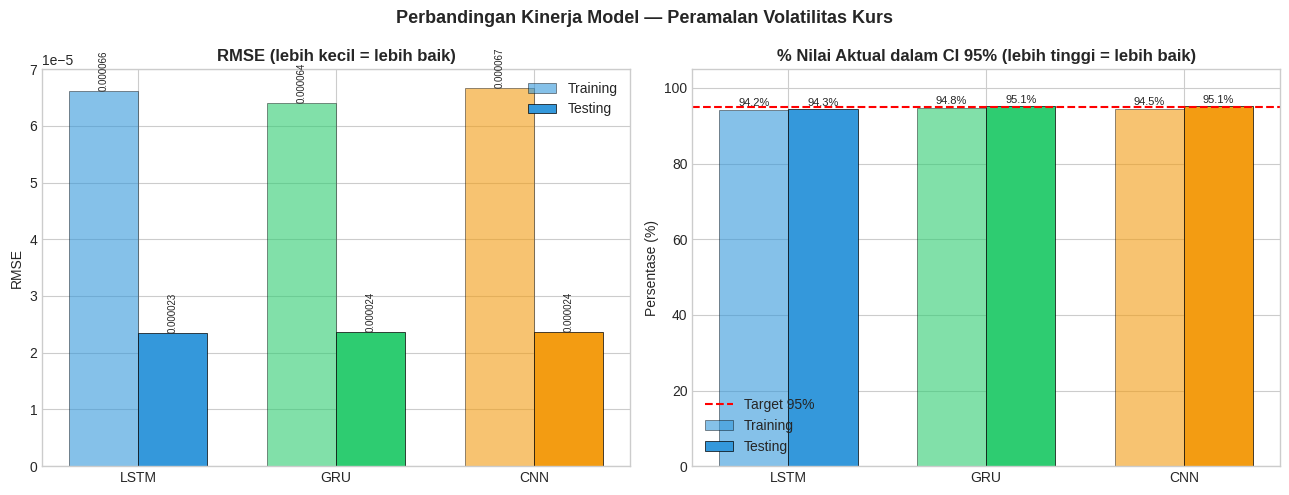

✅ Plot perbandingan disimpan: comparison_performance.png


In [18]:
# ── Plot Perbandingan RMSE ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Perbandingan Kinerja Model — Peramalan Volatilitas Kurs', fontsize=13, fontweight='bold')

methods = ['LSTM', 'GRU', 'CNN']
colors  = [COLORS[m] for m in methods]

rmse_train_vals = [rmse_lstm_train, rmse_gru_train, rmse_cnn_train]
rmse_test_vals  = [rmse_lstm_test,  rmse_gru_test,  rmse_cnn_test]
pct_train_vals  = [pct_l_train, pct_g2_train, pct_c_train]
pct_test_vals   = [pct_l_test,  pct_g2_test,  pct_c_test]

x = np.arange(3)
w = 0.35
ax = axes[0]
ax.bar(x - w/2, rmse_train_vals, w, label='Training', color=colors, alpha=0.6, edgecolor='black', linewidth=0.5)
ax.bar(x + w/2, rmse_test_vals,  w, label='Testing',  color=colors, alpha=1.0, edgecolor='black', linewidth=0.5)
ax.set_xticks(x); ax.set_xticklabels(methods)
ax.set_title('RMSE (lebih kecil = lebih baik)', fontweight='bold')
ax.set_ylabel('RMSE'); ax.legend()
for xi, (tr, te) in zip(x, zip(rmse_train_vals, rmse_test_vals)):
    ax.text(xi - w/2, tr, f'{tr:.6f}', ha='center', va='bottom', fontsize=7, rotation=90)
    ax.text(xi + w/2, te, f'{te:.6f}', ha='center', va='bottom', fontsize=7, rotation=90)

ax2 = axes[1]
ax2.bar(x - w/2, pct_train_vals, w, label='Training', color=colors, alpha=0.6, edgecolor='black', linewidth=0.5)
ax2.bar(x + w/2, pct_test_vals,  w, label='Testing',  color=colors, alpha=1.0, edgecolor='black', linewidth=0.5)
ax2.axhline(95, color='red', linestyle='--', linewidth=1.5, label='Target 95%')
ax2.set_xticks(x); ax2.set_xticklabels(methods)
ax2.set_title('% Nilai Aktual dalam CI 95% (lebih tinggi = lebih baik)', fontweight='bold')
ax2.set_ylabel('Persentase (%)'); ax2.legend(); ax2.set_ylim(0, 105)
for xi, (tr, te) in zip(x, zip(pct_train_vals, pct_test_vals)):
    ax2.text(xi - w/2, tr + 0.5, f'{tr:.1f}%', ha='center', va='bottom', fontsize=8)
    ax2.text(xi + w/2, te + 0.5, f'{te:.1f}%', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('comparison_performance.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot perbandingan disimpan: comparison_performance.png")


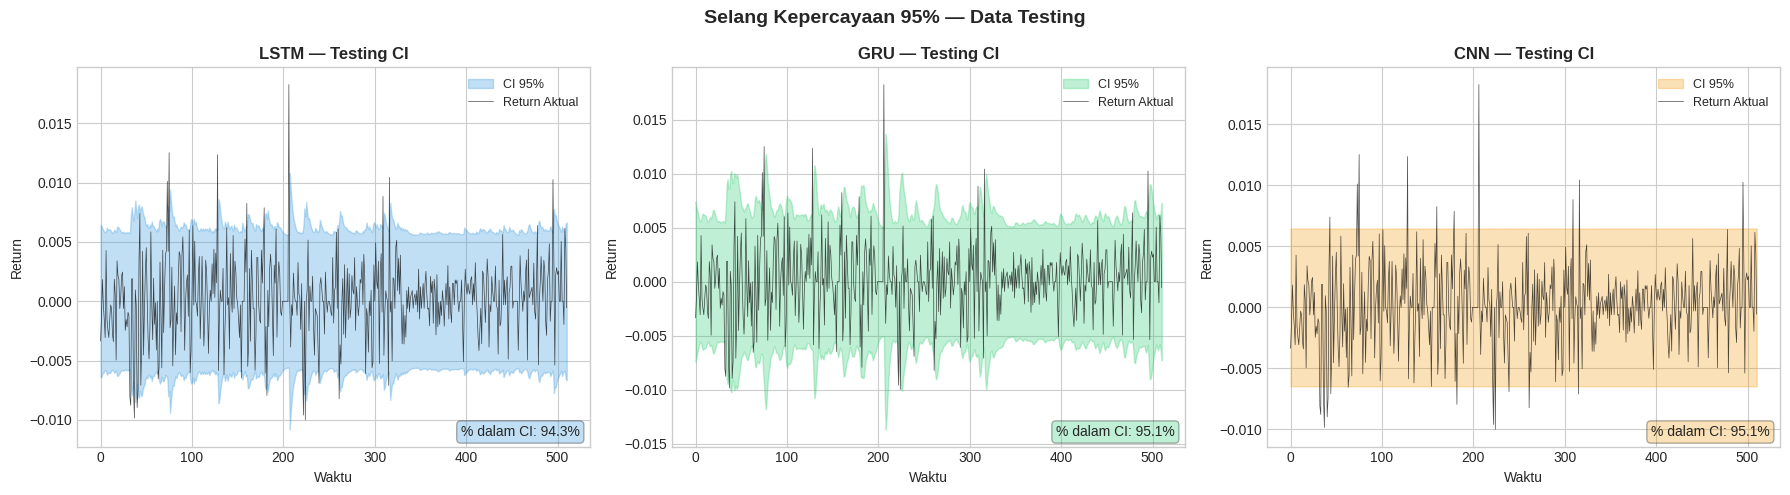

✅ Plot selang kepercayaan disimpan: ci_testing.png


In [19]:
# ── Plot Selang Kepercayaan — Data Testing ────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Selang Kepercayaan 95% — Data Testing', fontsize=14, fontweight='bold')

n_te = len(df_test_full)
x_ax = np.arange(n_te)
ret_te = df_test_full['Return'].values

def plot_ci(ax, pred_vol, color, title):
    from scipy.stats import norm
    z = norm.ppf(0.975)
    lo = -z * np.sqrt(np.abs(pred_vol))
    hi =  z * np.sqrt(np.abs(pred_vol))
    n_plot = min(len(lo), len(ret_te))
    ax.fill_between(x_ax[:n_plot], lo[:n_plot], hi[:n_plot], alpha=0.3, color=color, label='CI 95%')
    ax.plot(x_ax[:n_plot], ret_te[:n_plot], color='black', linewidth=0.5, alpha=0.7, label='Return Aktual')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Waktu'); ax.set_ylabel('Return')
    ax.legend(fontsize=9)
    inside = np.sum((ret_te[:n_plot] >= lo[:n_plot]) & (ret_te[:n_plot] <= hi[:n_plot]))
    pct = 100 * inside / n_plot
    ax.text(0.98, 0.02, f'% dalam CI: {pct:.1f}%', transform=ax.transAxes,
            ha='right', va='bottom', fontsize=10,
            bbox=dict(boxstyle='round,pad=0.3', facecolor=color, alpha=0.3))

plot_ci(axes[0], pred_te_lstm, COLORS['LSTM'], 'LSTM — Testing CI')
plot_ci(axes[1], pred_te_gru,  COLORS['GRU'],  'GRU — Testing CI')
plot_ci(axes[2], pred_te_cnn,  COLORS['CNN'],  'CNN — Testing CI')

plt.tight_layout()
plt.savefig('ci_testing.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot selang kepercayaan disimpan: ci_testing.png")


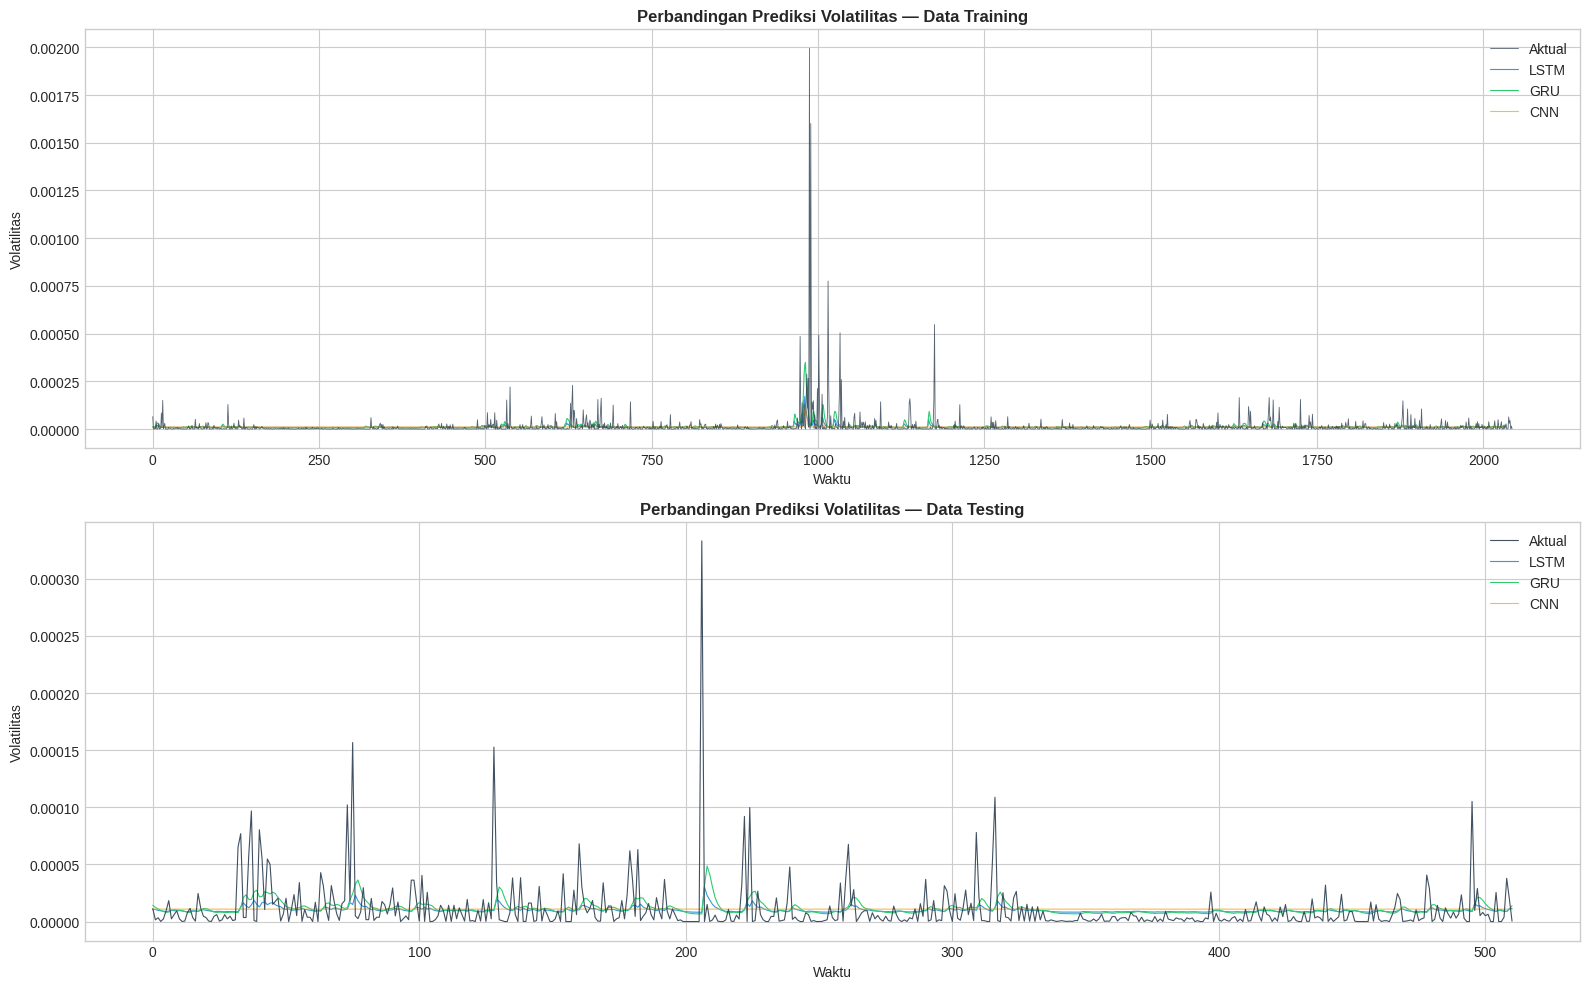

✅ Plot perbandingan prediksi disimpan: prediction_comparison.png


In [20]:
# ── Plot Perbandingan Prediksi vs Aktual — Data Testing ───────

n_plot = min(len(pred_te_lstm), len(pred_te_gru), len(pred_te_cnn), len(act_te_lstm))
x_ax2 = np.arange(n_plot)

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# ─── Training
axes[0].plot(df_train_full['Volatilitas'].values, color=COLORS['Aktual'],
             linewidth=0.6, alpha=0.8, label='Aktual', zorder=5)
axes[0].plot(pred_tr_lstm, color=COLORS['LSTM'],  linewidth=0.8, label='LSTM')
axes[0].plot(pred_tr_gru,  color=COLORS['GRU'],   linewidth=0.8, label='GRU')
axes[0].plot(pred_tr_cnn,  color=COLORS['CNN'],   linewidth=0.8, label='CNN', alpha=0.7)
axes[0].set_title('Perbandingan Prediksi Volatilitas — Data Training', fontweight='bold')
axes[0].set_xlabel('Waktu'); axes[0].set_ylabel('Volatilitas'); axes[0].legend()

# ─── Testing
axes[1].plot(df_test_full['Volatilitas'].values[:n_plot], color=COLORS['Aktual'],
             linewidth=0.8, alpha=0.9, label='Aktual', zorder=5)
axes[1].plot(pred_te_lstm[:n_plot], color=COLORS['LSTM'],  linewidth=0.8, label='LSTM')
axes[1].plot(pred_te_gru[:n_plot],  color=COLORS['GRU'],   linewidth=0.8, label='GRU')
axes[1].plot(pred_te_cnn[:n_plot],  color=COLORS['CNN'],   linewidth=0.8, label='CNN', alpha=0.7)
axes[1].set_title('Perbandingan Prediksi Volatilitas — Data Testing', fontweight='bold')
axes[1].set_xlabel('Waktu'); axes[1].set_ylabel('Volatilitas'); axes[1].legend()

plt.tight_layout()
plt.savefig('prediction_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Plot perbandingan prediksi disimpan: prediction_comparison.png")


## 🔮 11. Peramalan 30 Hari ke Depan (Model Terbaik — Otomatis)


In [21]:
# ── Tentukan Model Terbaik Berdasarkan RMSE Testing ─────────────
rmse_test_map = {
    'LSTM': rmse_lstm_test,
    'GRU' : rmse_gru_test,
    'CNN' : rmse_cnn_test,
}
best_model_name = min(rmse_test_map, key=rmse_test_map.get)

# Mapping model, scaler, dan build-function ke nama
model_map  = {'LSTM': lstm_model, 'GRU': gru_model, 'CNN': cnn_model}
scaler_map = {'LSTM': sc_lstm,    'GRU': sc_gru,    'CNN': sc_cnn}

best_model_obj    = model_map[best_model_name]
best_scaler       = scaler_map[best_model_name]

print("=" * 50)
print(f"🏆 Model Terbaik (RMSE Testing terkecil): {best_model_name}")
print(f"   RMSE Testing  : {rmse_test_map[best_model_name]:.7f}")
for m, v in rmse_test_map.items():
    marker = " ← BEST" if m == best_model_name else ""
    print(f"   {m}: {v:.7f}{marker}")
print("=" * 50)

# ── Forecast 30 Hari ke Depan menggunakan Model Terbaik ──────
N_FORECAST = 30

# Scaler dari semua data menggunakan scaler model terbaik
all_vol = df['Volatilitas'].values
all_sc  = best_scaler.transform(all_vol.reshape(-1, 1)).ravel()

# Ambil LOOKBACK terakhir sebagai seed
seed_seq    = all_sc[-LOOKBACK:].copy()
current_seq = seed_seq.reshape(1, LOOKBACK, 1)

forecasts_sc = []
for step in range(N_FORECAST):
    pred_sc = best_model_obj.predict(current_seq, verbose=0)[0, 0]
    forecasts_sc.append(pred_sc)
    current_seq = np.roll(current_seq, -1, axis=1)
    current_seq[0, -1, 0] = pred_sc

# Inverse transform
forecasts = best_scaler.inverse_transform(
    np.array(forecasts_sc).reshape(-1, 1)).ravel()

print(f"\n✅ Ramalan volatilitas {N_FORECAST} hari ke depan ({best_model_name}):")
print("-" * 40)
for i, f in enumerate(forecasts, 1):
    print(f"  Hari ke-{i:2d}: {f:.8f}")

# Simpan ke CSV (kolom dinamis sesuai model terbaik)
last_date      = df['Tanggal'].max()
forecast_dates = pd.date_range(start=last_date + pd.Timedelta(days=1),
                                periods=N_FORECAST, freq='B')
col_forecast   = f'Volatilitas_{best_model_name}'
df_forecast = pd.DataFrame({
    'Tanggal'   : forecast_dates,
    col_forecast: forecasts,
})
df_forecast.to_csv('forecast_30hari.csv', index=False)
print(f"\n✅ Ramalan disimpan: forecast_30hari.csv (kolom: {col_forecast})")


🏆 Model Terbaik (RMSE Testing terkecil): LSTM
   RMSE Testing  : 0.0000235
   LSTM: 0.0000235 ← BEST
   GRU: 0.0000236
   CNN: 0.0000236

✅ Ramalan volatilitas 30 hari ke depan (LSTM):
----------------------------------------
  Hari ke- 1: 0.00001032
  Hari ke- 2: 0.00001024
  Hari ke- 3: 0.00001019
  Hari ke- 4: 0.00001015
  Hari ke- 5: 0.00001010
  Hari ke- 6: 0.00001009
  Hari ke- 7: 0.00001007
  Hari ke- 8: 0.00001006
  Hari ke- 9: 0.00001003
  Hari ke-10: 0.00001003
  Hari ke-11: 0.00001003
  Hari ke-12: 0.00001003
  Hari ke-13: 0.00001003
  Hari ke-14: 0.00001003
  Hari ke-15: 0.00001003
  Hari ke-16: 0.00001003
  Hari ke-17: 0.00001003
  Hari ke-18: 0.00001003
  Hari ke-19: 0.00001003
  Hari ke-20: 0.00001003
  Hari ke-21: 0.00001003
  Hari ke-22: 0.00001003
  Hari ke-23: 0.00001003
  Hari ke-24: 0.00001003
  Hari ke-25: 0.00001003
  Hari ke-26: 0.00001003
  Hari ke-27: 0.00001003
  Hari ke-28: 0.00001003
  Hari ke-29: 0.00001003
  Hari ke-30: 0.00001003

✅ Ramalan disimpan: for

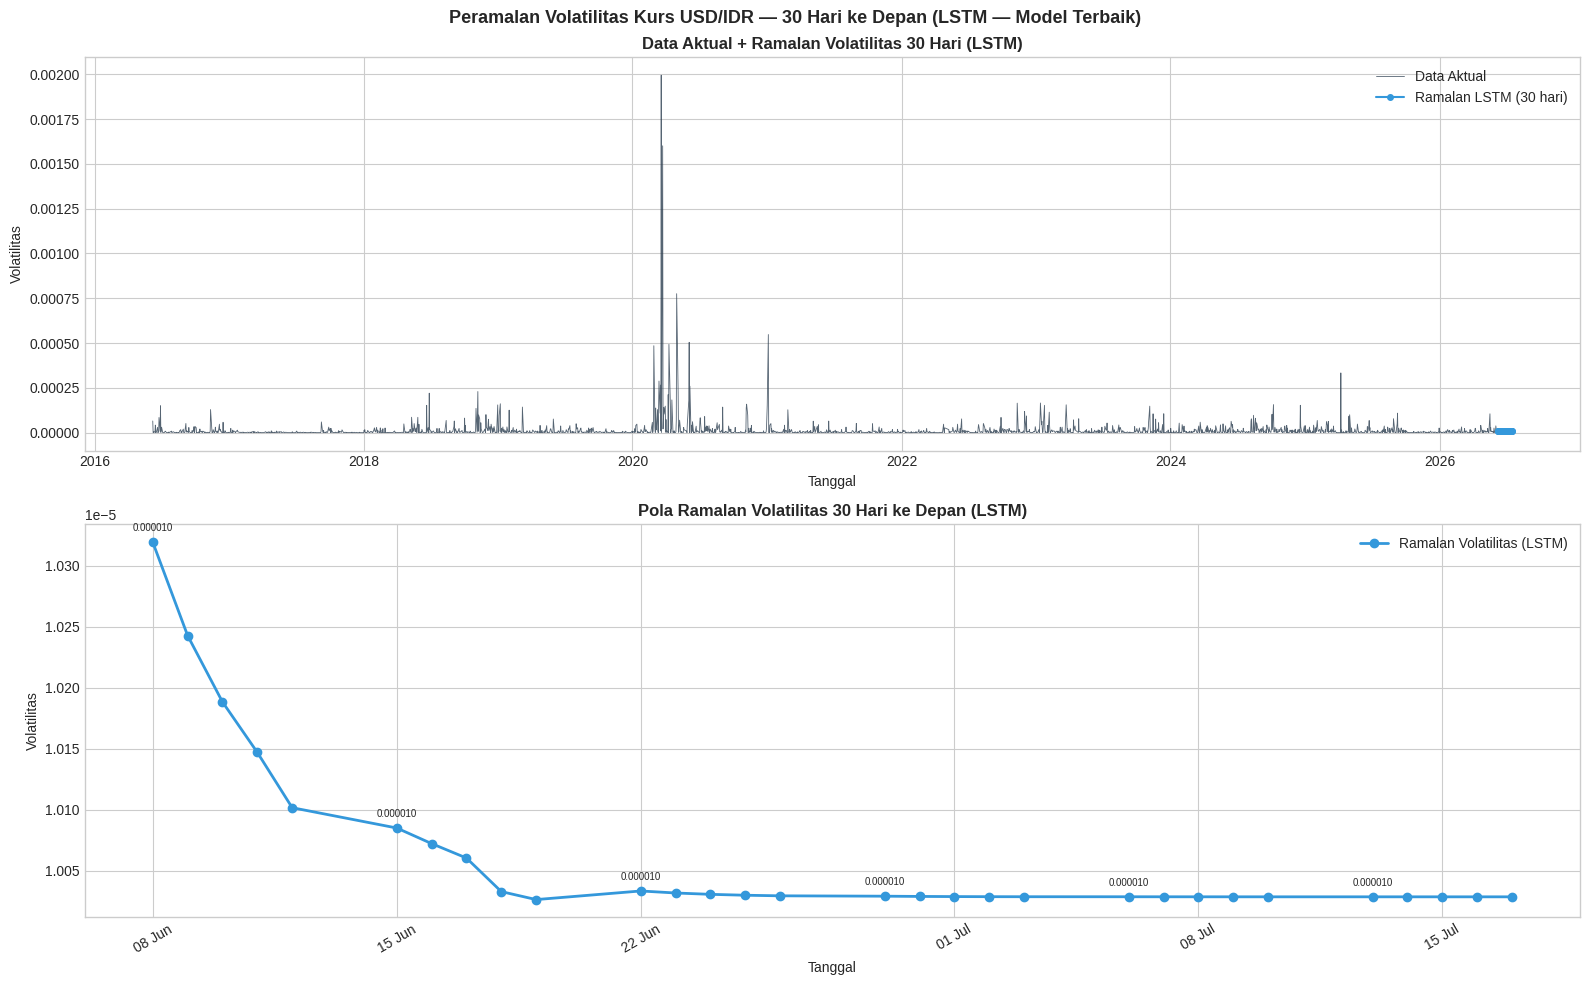

✅ Plot ramalan disimpan: forecast_30hari.png


In [22]:
# ── Visualisasi Ramalan 30 Hari ke Depan ─────────────────────

best_color = COLORS[best_model_name]
col_forecast = f'Volatilitas_{best_model_name}'

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle(f'Peramalan Volatilitas Kurs USD/IDR — 30 Hari ke Depan ({best_model_name} — Model Terbaik)',
             fontsize=13, fontweight='bold')

hist_dates = df['Tanggal'].values
hist_vol   = df['Volatilitas'].values

# Plot 1: Seluruh historis + forecast
axes[0].plot(hist_dates, hist_vol, color=COLORS['Aktual'], linewidth=0.6,
             alpha=0.8, label='Data Aktual')
axes[0].plot(df_forecast['Tanggal'], forecasts, color=best_color,
             marker='o', markersize=4, linewidth=1.5,
             label=f'Ramalan {best_model_name} (30 hari)')
axes[0].set_title(f'Data Aktual + Ramalan Volatilitas 30 Hari ({best_model_name})', fontweight='bold')
axes[0].set_xlabel('Tanggal'); axes[0].set_ylabel('Volatilitas')
axes[0].legend(); axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# Plot 2: Zoom — hanya forecast
axes[1].plot(df_forecast['Tanggal'], forecasts, color=best_color,
             marker='o', markersize=6, linewidth=2,
             label=f'Ramalan Volatilitas ({best_model_name})')
for i, (d, v) in enumerate(zip(df_forecast['Tanggal'], forecasts)):
    if i % 5 == 0:
        axes[1].annotate(f'{v:.6f}', (d, v), textcoords='offset points',
                         xytext=(0, 8), ha='center', fontsize=7)
axes[1].set_title(f'Pola Ramalan Volatilitas 30 Hari ke Depan ({best_model_name})', fontweight='bold')
axes[1].set_xlabel('Tanggal'); axes[1].set_ylabel('Volatilitas')
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
plt.setp(axes[1].xaxis.get_majorticklabels(), rotation=30)
axes[1].legend()

plt.tight_layout()
plt.savefig('forecast_30hari.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"✅ Plot ramalan disimpan: forecast_30hari.png")


## 💾 12. Export Semua Hasil untuk Streamlit Dashboard


In [23]:
import joblib, json

# ── 1. Data historis bersih
df.to_csv('data_kurs_bersih.csv', index=False)

# ── 2. Prediksi semua model (testing)
n_min = min(len(pred_te_lstm), len(pred_te_gru), len(pred_te_cnn))
df_pred_test = pd.DataFrame({
    'Tanggal'            : df_test_full['Tanggal'].values[:n_min],
    'Volatilitas_Aktual' : df_test_full['Volatilitas'].values[:n_min],
    'Return_Aktual'      : df_test_full['Return'].values[:n_min],
    'LSTM'               : pred_te_lstm[:n_min],
    'GRU'                : pred_te_gru[:n_min],
    'CNN'                : pred_te_cnn[:n_min],
})
df_pred_test.to_csv('predictions_testing.csv', index=False)

# ── 3. Prediksi training
n_min_tr = min(len(pred_tr_lstm), len(pred_tr_gru), len(pred_tr_cnn))
df_pred_train = pd.DataFrame({
    'Volatilitas_Aktual': act_tr_lstm[:n_min_tr],
    'LSTM'              : pred_tr_lstm[:n_min_tr],
    'GRU'               : pred_tr_gru[:n_min_tr],
    'CNN'               : pred_tr_cnn[:n_min_tr],
})
df_pred_train.to_csv('predictions_training.csv', index=False)

# ── 4. Ringkasan metrics (tambah best_model_name)
metrics = {
    'RMSE': {
        'LSTM' : {'train': float(rmse_lstm_train), 'test': float(rmse_lstm_test)},
        'GRU'  : {'train': float(rmse_gru_train),  'test': float(rmse_gru_test)},
        'CNN'  : {'train': float(rmse_cnn_train),  'test': float(rmse_cnn_test)},
    },
    'CI_pct': {
        'LSTM' : {'train': float(pct_l_train),  'test': float(pct_l_test)},
        'GRU'  : {'train': float(pct_g2_train), 'test': float(pct_g2_test)},
        'CNN'  : {'train': float(pct_c_train),  'test': float(pct_c_test)},
    },
    'best_params': {
        'LSTM' : best_lstm,
        'GRU'  : best_gru,
        'CNN'  : best_cnn,
    },
    'best_model_name': best_model_name,   # ← disimpan eksplisit untuk dashboard
}
with open('metrics_summary.json', 'w') as f:
    json.dump(metrics, f, indent=2)

# ── 5. Simpan model terbaik + scalernya
best_model_obj.save(f'{best_model_name.lower()}_model.keras')
joblib.dump(best_scaler, f'scaler_{best_model_name.lower()}.pkl')

# Tetap simpan semua scaler agar dashboard bisa load jika diperlukan
joblib.dump(sc_lstm, 'scaler_lstm.pkl')
joblib.dump(sc_gru,  'scaler_gru.pkl')
joblib.dump(sc_cnn,  'scaler_cnn.pkl')

print("✅ Semua file hasil berhasil disimpan!")
print()
print(f"Model terbaik: {best_model_name} (RMSE test: {rmse_test_map[best_model_name]:.7f})")
print()
print("File yang tersedia untuk Streamlit Dashboard:")
files_list = [
    'data_kurs_bersih.csv                  — Data historis bersih',
    'predictions_testing.csv               — Prediksi semua model (test)',
    'predictions_training.csv              — Prediksi semua model (train)',
    f'forecast_30hari.csv                  — Ramalan {best_model_name} 30 hari',
    'comparison_rmse.csv                   — Tabel perbandingan RMSE',
    'comparison_pct.csv                    — Tabel perbandingan % CI',
    'metrics_summary.json                  — Semua metrics + best_model_name',
    f'{best_model_name.lower()}_model.keras — Model {best_model_name} tersimpan',
    f'scaler_{best_model_name.lower()}.pkl — Scaler model terbaik',
]
for f in files_list:
    print(f"  📄 {f}")


✅ Semua file hasil berhasil disimpan!

Model terbaik: LSTM (RMSE test: 0.0000235)

File yang tersedia untuk Streamlit Dashboard:
  📄 data_kurs_bersih.csv                  — Data historis bersih
  📄 predictions_testing.csv               — Prediksi semua model (test)
  📄 predictions_training.csv              — Prediksi semua model (train)
  📄 forecast_30hari.csv                  — Ramalan LSTM 30 hari
  📄 comparison_rmse.csv                   — Tabel perbandingan RMSE
  📄 comparison_pct.csv                    — Tabel perbandingan % CI
  📄 metrics_summary.json                  — Semua metrics + best_model_name
  📄 lstm_model.keras — Model LSTM tersimpan
  📄 scaler_lstm.pkl — Scaler model terbaik


In [24]:
# ── Download semua file sekaligus ────────────────────────────
import zipfile, os

output_files = [
    'data_kurs_bersih.csv', 'predictions_testing.csv', 'predictions_training.csv',
    'forecast_30hari.csv', 'comparison_rmse.csv', 'comparison_pct.csv',
    'metrics_summary.json',
    f'{best_model_name.lower()}_model.keras',
    f'scaler_{best_model_name.lower()}.pkl',
    'scaler_lstm.pkl', 'scaler_gru.pkl', 'scaler_cnn.pkl',
    'eda_kurs.png', 'comparison_performance.png', 'ci_testing.png',
    'prediction_comparison.png', 'forecast_30hari.png',
]

with zipfile.ZipFile('hasil_volatilitas_kurs.zip', 'w') as zf:
    for fname in output_files:
        if os.path.exists(fname):
            zf.write(fname)
            print(f"  ✅ {fname}")
        else:
            print(f"  ⚠️  {fname} tidak ditemukan")

from google.colab import files
files.download('hasil_volatilitas_kurs.zip')
print("\n✅ Download ZIP berhasil!")


  ✅ data_kurs_bersih.csv
  ✅ predictions_testing.csv
  ✅ predictions_training.csv
  ✅ forecast_30hari.csv
  ✅ comparison_rmse.csv
  ✅ comparison_pct.csv
  ✅ metrics_summary.json
  ✅ lstm_model.keras
  ✅ scaler_lstm.pkl
  ✅ scaler_lstm.pkl
  ✅ scaler_gru.pkl
  ✅ scaler_cnn.pkl
  ✅ eda_kurs.png
  ✅ comparison_performance.png
  ✅ ci_testing.png
  ✅ prediction_comparison.png
  ✅ forecast_30hari.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Download ZIP berhasil!


## 📌 13. Catatan untuk Streamlit Dashboard

File yang perlu diload di Streamlit:

```python
import pandas as pd, numpy as np, json, joblib
import plotly.graph_objects as go
import plotly.express as px

# Load data
df_hist   = pd.read_csv('data_kurs_bersih.csv', parse_dates=['Tanggal'])
df_pred   = pd.read_csv('predictions_testing.csv', parse_dates=['Tanggal'])
df_fore   = pd.read_csv('forecast_30hari.csv', parse_dates=['Tanggal'])
with open('metrics_summary.json') as f:
    metrics = json.load(f)
```

**Struktur Dashboard yang Disarankan:**
- 📊 **Tab 1 — Overview**: Time series kurs, return, volatilitas
- 📉 **Tab 2 — Perbandingan Model**: Bar chart RMSE + % CI, tabel perbandingan
- 🔮 **Tab 3 — Selang Kepercayaan**: Plot CI per model (LSTM, GRU, CNN)
- 📈 **Tab 4 — Ramalan 30 Hari**: Plot forecast GRU
- ⚙️ **Tab 5 — Hyperparameter Terbaik**: Tabel konfigurasi semua model

**Tips Streamlit:**
- Gunakan `st.tabs()` untuk navigasi bersih
- `plotly` lebih interaktif vs `matplotlib` di Streamlit
- `st.metric()` untuk showcase RMSE & % CI di hero section
